# Exploratory Data Analysis ? Model A (Knowledge)
Task #17: Raw data exploration for ASSISTments 2009-2010 (`skill_builder_data.csv`) and EdNet (`KT1` + `questions.csv`).
Read-only exploration; raw files in `ml/data/raw/` are never modified.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

RAW_DIR = Path("../../data/raw/knowledge")
ASSISTMENTS_PATH = RAW_DIR / "skill_builder_data.csv"
KT1_DIR = RAW_DIR / "EdNet-KT1" / "KT1"
QUESTIONS_PATH = RAW_DIR / "EdNet-Contents" / "contents" / "questions.csv"

## 1. ASSISTments 2009-2010 (`skill_builder_data.csv`)
Track shape, missing values per column, duplicate `order_id`s, unique students/skills/problems, overall correct rate, and histograms for answers per student and response times.

In [5]:
assist_df = pd.read_csv(ASSISTMENTS_PATH, encoding="latin1", low_memory=False)

print(f"Shape (rows, cols): {assist_df.shape}")
print("\nMissing values per column:")
print(assist_df.isna().sum()[assist_df.isna().sum() > 0])

dup_orders = assist_df["order_id"].duplicated().sum()
print(f"\nDuplicate order_id count: {dup_orders:,}")

n_students = assist_df["user_id"].nunique(dropna=True)
n_skills = assist_df["skill_id"].nunique(dropna=True)
n_problems = assist_df["problem_id"].nunique(dropna=True)
print(f"Unique students (user_id): {n_students:,}")
print(f"Unique skills (skill_id): {n_skills:,}")
print(f"Unique problems (problem_id): {n_problems:,}")

overall_correct_rate = assist_df["correct"].mean()
print(f"Overall correct rate: {overall_correct_rate:.4%}")

Shape (rows, cols): (525534, 30)

Missing values per column:
skill_id                 66326
skill_name               78690
answer_id               476856
answer_text              94784
bottom_hint             445627
opportunity_original     76314
dtype: int64

Duplicate order_id count: 178,674
Unique students (user_id): 4,217
Unique skills (skill_id): 123
Unique problems (problem_id): 26,688
Overall correct rate: 67.9471%


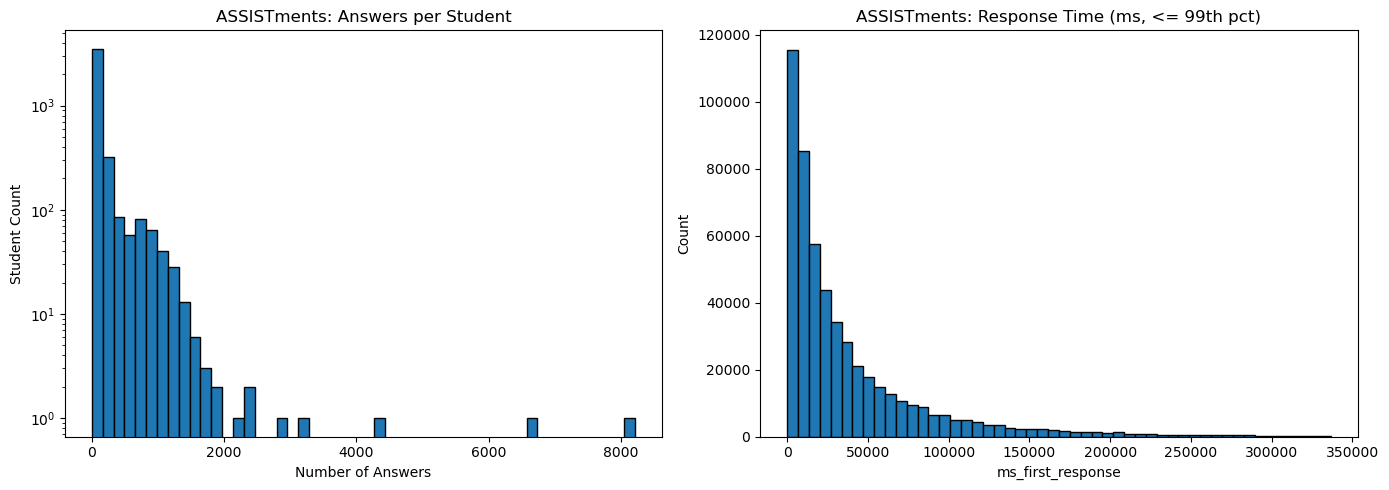

In [6]:
answers_per_student = assist_df.groupby("user_id").size()
response_times = assist_df["ms_first_response"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(answers_per_student, bins=50, edgecolor="black")
axes[0].set_title("ASSISTments: Answers per Student")
axes[0].set_xlabel("Number of Answers")
axes[0].set_ylabel("Student Count")
axes[0].set_yscale("log")

clipped_rt = response_times[(response_times >= 0) & (response_times <= response_times.quantile(0.99))]
axes[1].hist(clipped_rt, bins=50, edgecolor="black")
axes[1].set_title("ASSISTments: Response Time (ms, <= 99th pct)")
axes[1].set_xlabel("ms_first_response")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

## 2. EdNet Sample (`EdNet-KT1/KT1` + `questions.csv`)
Inspect shape, missing values, unique users/questions/tags, overall accuracy, and distributions.

In [8]:
questions_df = pd.read_csv(QUESTIONS_PATH)
print(f"questions.csv shape: {questions_df.shape}")
print("questions.csv missing values:")
print(questions_df.isna().sum())

kt1_files = sorted(KT1_DIR.glob("*.csv"))
print(f"\nTotal KT1 student files found: {len(kt1_files):,}")

sample_size = min(2000, len(kt1_files))
rng = np.random.default_rng(RANDOM_SEED)
sampled_files = rng.choice(kt1_files, size=sample_size, replace=False)
print(f"Sampling {sample_size:,} student files for fast EDA...")

use_cols = ["question_id", "user_answer", "elapsed_time"]
kt1_frames = []
for file_path in sampled_files:
    temp_df = pd.read_csv(file_path, usecols=use_cols)
    temp_df["user_id"] = Path(file_path).stem
    kt1_frames.append(temp_df)

ednet_df = pd.concat(kt1_frames, ignore_index=True)
ednet_merged = ednet_df.merge(
    questions_df[["question_id", "correct_answer", "tags"]],
    on="question_id",
    how="left",
)
ednet_merged["is_correct"] = (
    ednet_merged["user_answer"].astype(str).str.strip().str.lower()
    == ednet_merged["correct_answer"].astype(str).str.strip().str.lower()
)

print(f"\nEdNet sampled merged shape (rows, cols): {ednet_merged.shape}")
print("\nEdNet missing values per column:")
print(ednet_merged.isna().sum())

print(f"\nUnique users (in sample): {ednet_merged['user_id'].nunique():,}")
print(f"Unique questions: {ednet_merged['question_id'].nunique():,}")
print(f"Unique tag combinations: {ednet_merged['tags'].nunique(dropna=True):,}")
print(f"Overall correct rate: {ednet_merged['is_correct'].mean():.4%}")

questions.csv shape: (13169, 7)
questions.csv missing values:
question_id       0
bundle_id         0
explanation_id    0
correct_answer    0
part              0
tags              0
deployed_at       0
dtype: int64

Total KT1 student files found: 181,949
Sampling 2,000 student files for fast EDA...

EdNet sampled merged shape (rows, cols): (446966, 7)

EdNet missing values per column:
question_id        0
user_answer       39
elapsed_time       0
user_id            0
correct_answer     0
tags               0
is_correct         0
dtype: int64

Unique users (in sample): 2,000
Unique questions: 12,095
Unique tag combinations: 1,766
Overall correct rate: 65.3231%


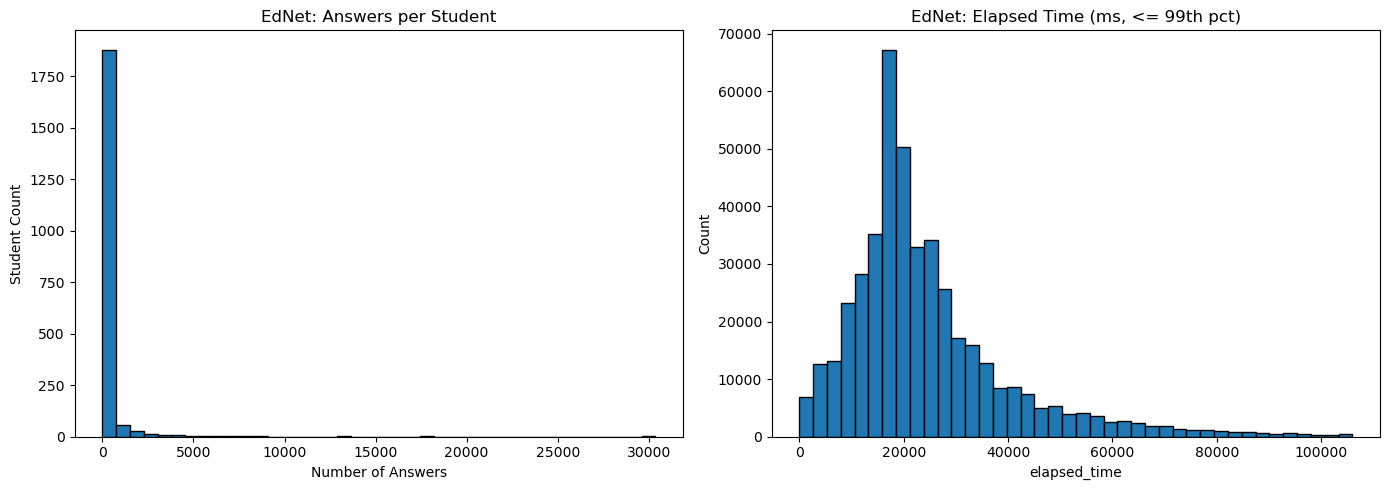

In [9]:
ednet_answers_per_user = ednet_merged.groupby("user_id").size()
ednet_elapsed = ednet_merged["elapsed_time"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ednet_answers_per_user, bins=40, edgecolor="black")
axes[0].set_title("EdNet: Answers per Student")
axes[0].set_xlabel("Number of Answers")
axes[0].set_ylabel("Student Count")

clipped_elapsed = ednet_elapsed[(ednet_elapsed >= 0) & (ednet_elapsed <= ednet_elapsed.quantile(0.99))]
axes[1].hist(clipped_elapsed, bins=40, edgecolor="black")
axes[1].set_title("EdNet: Elapsed Time (ms, <= 99th pct)")
axes[1].set_xlabel("elapsed_time")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()